# Segmentasi Transaksi & Deteksi Anomali Nasabah (Clustering)

## Tujuan Proyek
Mengelompokkan data transaksi perbankan memakai **K-Means Clustering** untuk mengenali pola perilaku nasabah dan transaksi mencurigakan. Label cluster dari notebook ini akan dipakai sebagai target pada tahap klasifikasi dan dashboard interaktif.

---

# 1. Import Library & Cek Data Awal
Siapkan library yang dipakai dan lihat kondisi data mentah sebelum dibersihkan.

In [1]:
# Hapus tanda # jika library belum terinstal
# %pip install pandas matplotlib seaborn scikit-learn joblib openpyxl

import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import joblib

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

print("Library siap.")

Library siap.


## 1.1 Muat Dataset
Baca data dari `raw.xlsx` (atau URL Google Sheets jika file lokal tidak ada), lalu salin ke `df` agar data mentah tetap aman.

In [2]:
local_path = 'raw.xlsx'
backup_url = 'https://docs.google.com/spreadsheets/d/e/2PACX-1vTbg5WVW6W3c8SPNUGc3A3AL-AG32TPEQGpdzARfNICMsLFI0LQj0jporhsLCeVhkN5AoRsTkn08AYl/pub?output=csv'

if os.path.exists(local_path):
    df_raw = pd.read_excel(local_path)
    print(f"Data dimuat dari: {local_path}")
else:
    df_raw = pd.read_csv(backup_url)
    print("Data dimuat dari URL Google Sheets.")

df = df_raw.copy()
print(f"Ukuran data: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Data dimuat dari: raw.xlsx
Ukuran data: 2537 baris, 16 kolom


,TransactionID,AccountID,TransactionAmount,PreviousTransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.00,Doctor,81.00,1.00,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.00,Doctor,141.00,1.00,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.00,Student,56.00,1.00,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.00,Student,25.00,1.00,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.00,1.00,7429.40,2024-11-04 08:06:39


## 1.2 Cek Tipe Data, Missing Values, dan Duplikat
Periksa tipe tiap kolom, jumlah data kosong, dan baris ganda.

In [3]:
print(f"Baris duplikat: {df.duplicated().sum()}\n")

data_summary = pd.DataFrame({
    'Tipe Data': df.dtypes,
    'Non-Null': df.notnull().sum(),
    'Missing': df.isnull().sum(),
    'Missing (%)': (df.isnull().sum() / len(df)) * 100,
    'Nilai Unik': df.nunique()
})
display(data_summary)

Baris duplikat: 21



,Tipe Data,Non-Null,Missing,Missing (%),Nilai Unik
TransactionID,str,2508,29,1.14,2484
AccountID,str,2516,21,0.83,495
TransactionAmount,float64,2511,26,1.02,2433
PreviousTransactionDate,datetime64[us],2509,28,1.10,2485
TransactionType,str,2507,30,1.18,2
Location,str,2507,30,1.18,43
DeviceID,str,2507,30,1.18,681
IP Address,str,2517,20,0.79,591
MerchantID,str,2514,23,0.91,100
Channel,str,2510,27,1.06,3


## 1.3 Statistik Deskriptif Awal
Cek rentang angka numerik (waspadai nilai tidak wajar) dan kategori paling sering muncul pada kolom teks.

In [4]:
print("=== Fitur Numerik ===")
display(df.describe().T)

print("\n=== Fitur Kategorikal ===")
display(df.describe(include=['object', 'string']).T)

=== Fitur Numerik ===


,count,mean,min,25%,50%,75%,max,std
TransactionAmount,2511.00,297.66,0.26,81.31,211.36,413.11,1919.11,292.23
PreviousTransactionDate,2509,2023-07-05 17:33:20.831805,2023-01-02 16:00:06,2023-04-03 16:14:34,2023-07-07 17:40:58,2023-10-06 18:44:37,2024-01-01 18:21:50,NaN
CustomerAge,2519.00,44.68,18.00,27.00,45.00,59.00,80.00,17.84
TransactionDuration,2511.00,119.42,10.00,63.00,112.00,161.00,300.00,70.08
LoginAttempts,2516.00,1.12,1.00,1.00,1.00,1.00,5.00,0.59
AccountBalance,2510.00,5113.44,101.25,1504.73,4734.11,7672.69,14977.99,3897.98
TransactionDate,2513,2024-11-04 08:09:22.576999,2024-11-04 08:06:23,2024-11-04 08:07:54,2024-11-04 08:09:23,2024-11-04 08:10:54,2024-11-04 08:12:23,NaN



=== Fitur Kategorikal ===


,count,unique,top,freq
TransactionID,2508,2484,TX000026,2
AccountID,2516,495,AC00202,12
TransactionType,2507,2,Debit,1942
Location,2507,43,Fort Worth,71
DeviceID,2507,681,D000548,9
IP Address,2517,591,200.136.146.93,12
MerchantID,2514,100,M026,46
Channel,2510,3,Branch,868
CustomerOccupation,2514,4,Student,657


---

# 2. Pembersihan Data (Data Cleaning)
1. **Hapus duplikat**: buang `21` baris ganda agar tidak membobot berlebih.
2. **Hapus kolom tidak relevan**: buang kolom ID & IP (`TransactionID`, `AccountID`, `DeviceID`, `MerchantID`, `IP Address`) dan tanggal (`TransactionDate`, `PreviousTransactionDate`) karena `TransactionDate` hanya mencatat rentang 6 menit yang sama.
3. **Isi nilai kosong (imputasi)**: pakai **median** untuk kolom numerik (tahan *outlier*) dan **modus** untuk kolom teks, karena porsi data kosong kecil (`< 1.2%` per kolom).

In [5]:
initial_rows = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplikat dihapus: {initial_rows - len(df)} baris (sisa {len(df)} baris)")

cols_to_drop = [
    'TransactionID', 'AccountID', 'DeviceID', 'MerchantID',
    'IP Address', 'PreviousTransactionDate', 'TransactionDate'
]
df = df.drop(columns=cols_to_drop)

print(f"Kolom tersisa ({df.shape[1]}): {df.columns.tolist()}")

Duplikat dihapus: 21 baris (sisa 2516 baris)
Kolom tersisa (9): ['TransactionAmount', 'TransactionType', 'Location', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']


## 2.1 Imputasi Nilai Kosong
Isi nilai kosong pada kolom numerik dengan median dan kolom kategorikal dengan modus.

In [6]:
numerical_cols = df.select_dtypes(include='number').columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values setelah imputasi:")
print(df.isnull().sum())
print(f"\nUkuran data bersih: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Missing values setelah imputasi:
TransactionAmount      0
TransactionType        0
Location               0
Channel                0
CustomerAge            0
CustomerOccupation     0
TransactionDuration    0
LoginAttempts          0
AccountBalance         0
dtype: int64

Ukuran data bersih: 2516 baris, 9 kolom


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,Debit,San Diego,ATM,70.00,Doctor,81.00,1.00,5112.21
1,376.24,Debit,Houston,ATM,68.00,Doctor,141.00,1.00,13758.91
2,126.29,Debit,Mesa,Online,19.00,Student,56.00,1.00,1122.35
3,184.50,Debit,Raleigh,Online,26.00,Student,25.00,1.00,8569.06
4,13.45,Credit,Atlanta,Online,45.00,Student,198.00,1.00,7429.40


---

# 3. Feature Engineering & EDA
1. **`Balance_Ratio`**: rasio `TransactionAmount / AccountBalance` untuk melihat seberapa besar porsi saldo yang ditarik tiap transaksi.
2. **EDA**: cek distribusi data, *outlier* alami (seperti `LoginAttempts > 1`), dan korelasi antar fitur.

In [7]:
df['Balance_Ratio'] = df['TransactionAmount'] / df['AccountBalance']
numerical_cols = df.select_dtypes(include='number').columns.tolist()

print(f"Fitur numerik ({len(numerical_cols)}): {numerical_cols}\n")
print("=== Statistik Fitur Numerik ===")
display(df[numerical_cols].describe().T)

print("\n=== Sebaran LoginAttempts ===")
login_counts = pd.DataFrame({
    'Jumlah': df['LoginAttempts'].value_counts().sort_index(),
    'Persentase (%)': df['LoginAttempts'].value_counts(normalize=True).sort_index() * 100
})
display(login_counts)

Fitur numerik (6): ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'Balance_Ratio']

=== Statistik Fitur Numerik ===


,count,mean,std,min,25%,50%,75%,max
TransactionAmount,2516.00,296.85,291.09,0.26,83.14,211.36,409.59,1919.11
CustomerAge,2516.00,44.65,17.75,18.00,27.00,45.00,59.00,80.00
TransactionDuration,2516.00,119.47,69.63,10.00,63.00,112.50,161.00,300.00
LoginAttempts,2516.00,1.12,0.59,1.00,1.00,1.00,1.00,5.00
AccountBalance,2516.00,5113.43,3876.77,101.25,1519.37,4737.84,7640.99,14977.99
Balance_Ratio,2516.00,0.20,0.51,0.00,0.02,0.05,0.15,7.90



=== Sebaran LoginAttempts ===


,Jumlah,Persentase (%)
LoginAttempts,,
1.00,2396,95.23
2.00,27,1.07
3.00,31,1.23
4.00,31,1.23
5.00,31,1.23


## 3.1 Distribusi Fitur Numerik
Histogram melihat bentuk sebaran (normal atau miring); boxplot menandai *outlier* alami yang sengaja dipertahankan.

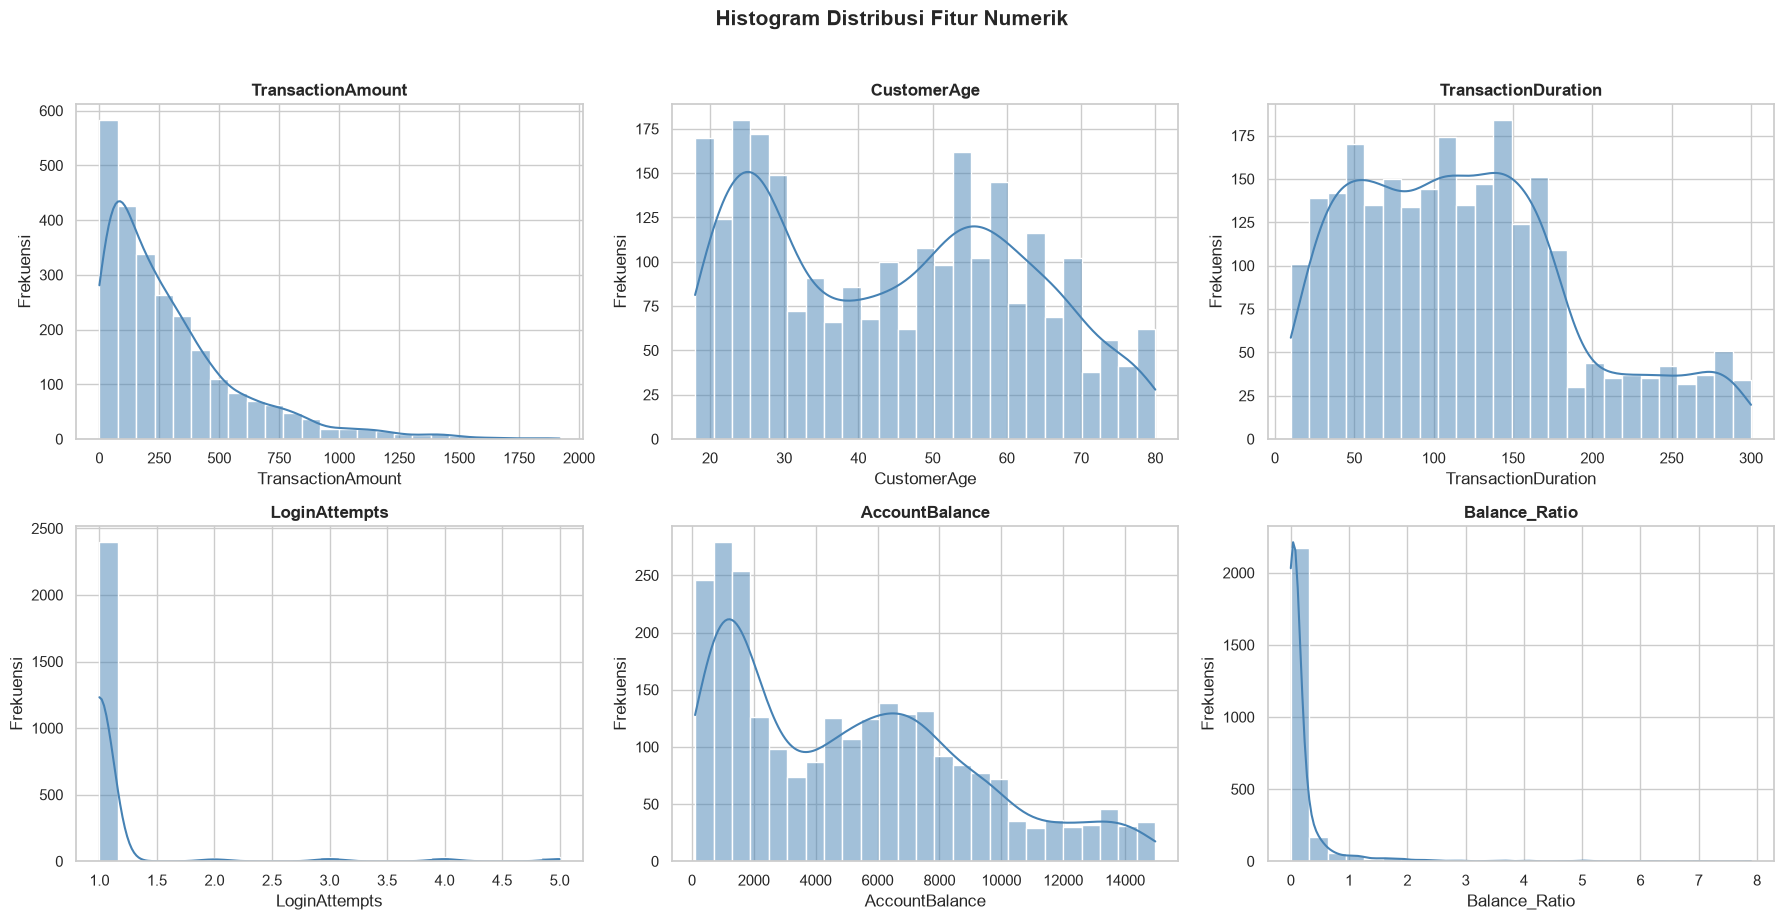

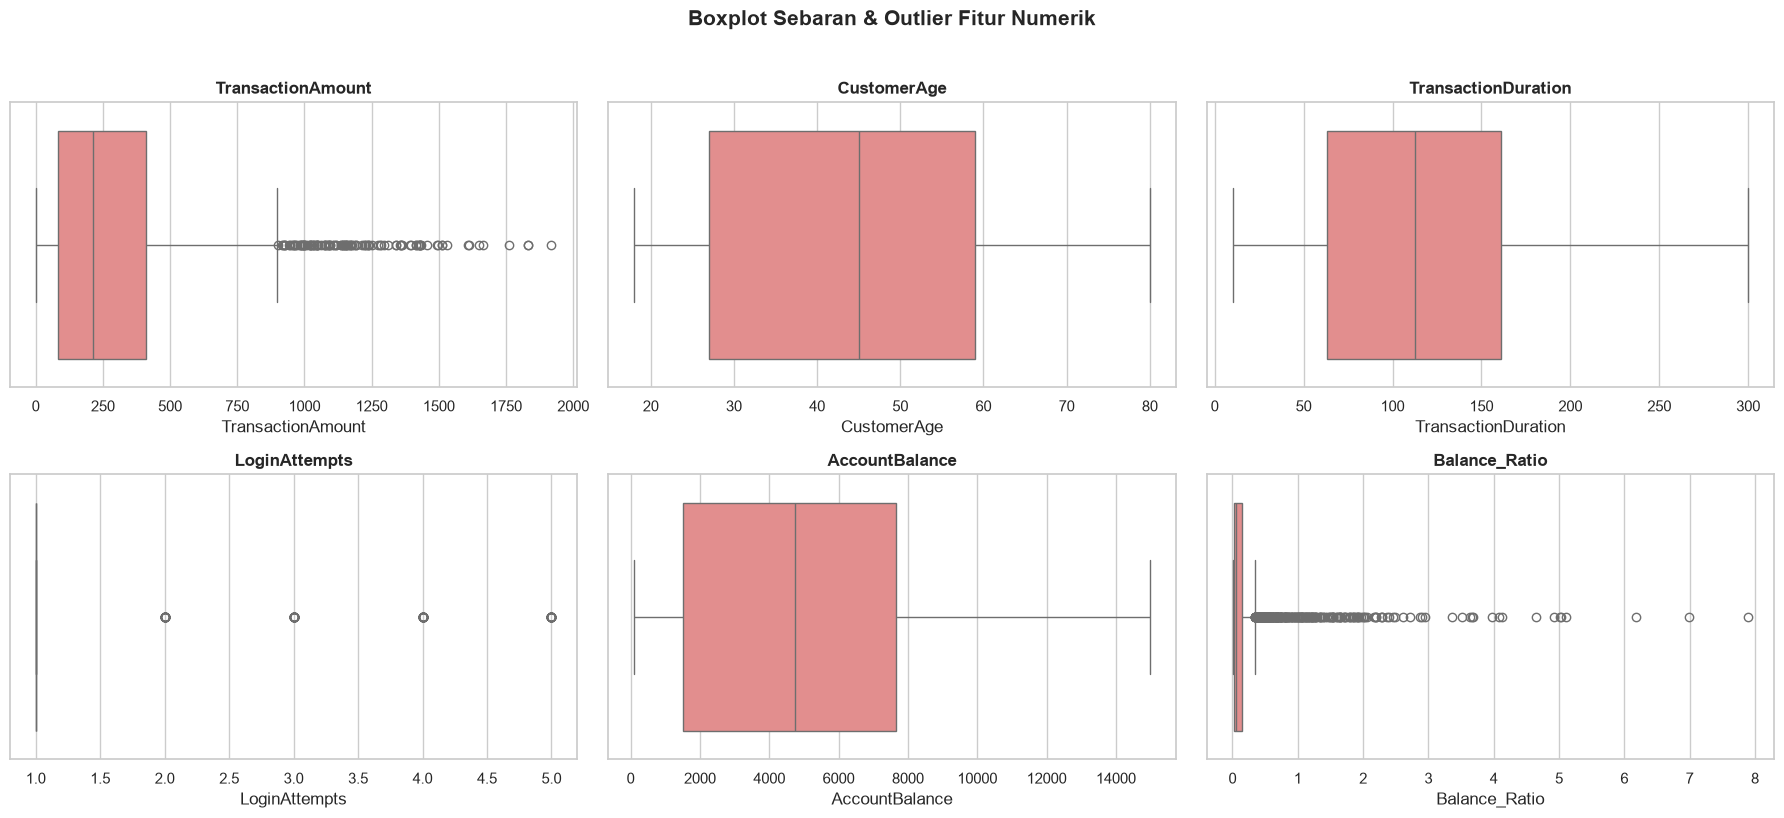

In [8]:
def plot_numeric_grid(data, cols, kind, title, figsize):
    """Plot grid 2x3 histogram atau boxplot untuk daftar fitur numerik."""
    fig, axes = plt.subplots(2, 3, figsize=figsize)
    for ax, col in zip(axes.flatten(), cols):
        if kind == 'hist':
            sns.histplot(data[col], bins=25, kde=True, color='steelblue', ax=ax)
            ax.set_ylabel('Frekuensi')
        else:
            sns.boxplot(x=data[col], color='lightcoral', ax=ax)
        ax.set_title(col, fontsize=12, fontweight='bold')
        ax.set_xlabel(col)
    plt.suptitle(title, fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

plot_numeric_grid(df, numerical_cols, 'hist', 'Histogram Distribusi Fitur Numerik', (18, 9))
plot_numeric_grid(df, numerical_cols, 'box', 'Boxplot Sebaran & Outlier Fitur Numerik', (18, 8))

## 3.2 Fitur Kategorikal & Korelasi
Cek proporsi kategori utama (`Location` tidak diplot karena ada `43` kota) dan korelasi antar fitur numerik agar tidak ada fitur ganda.

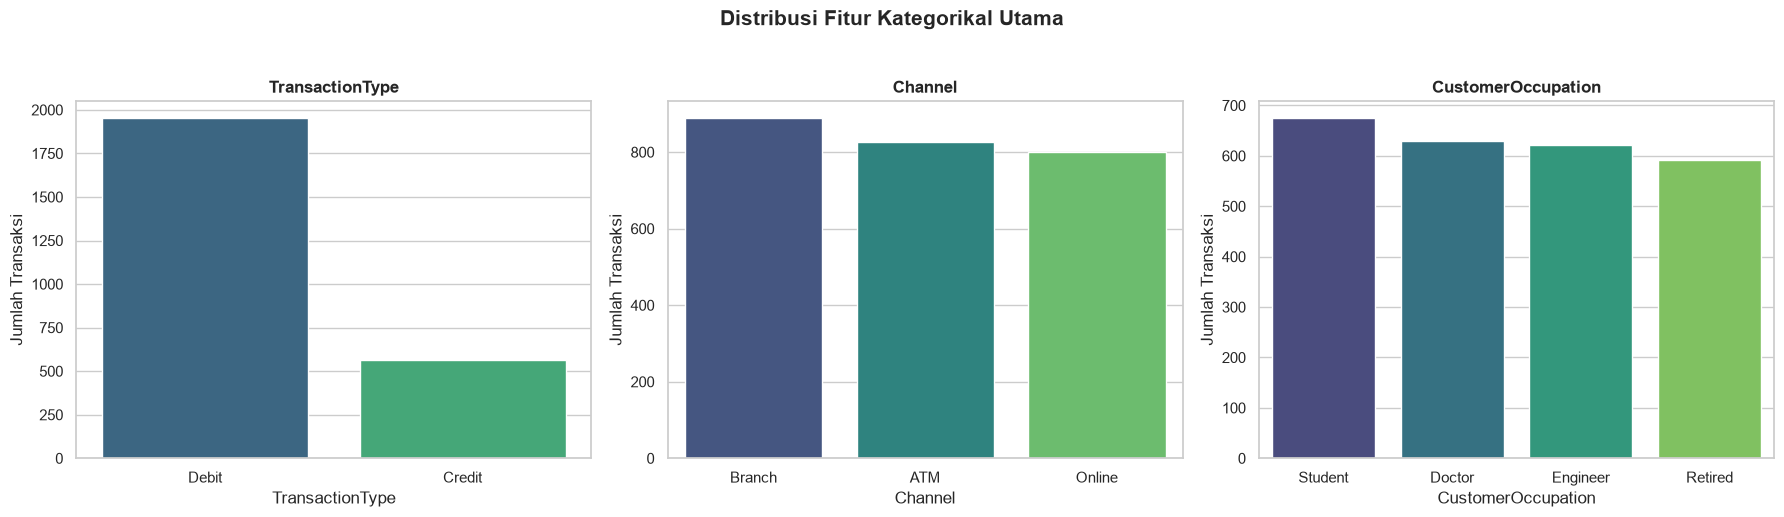

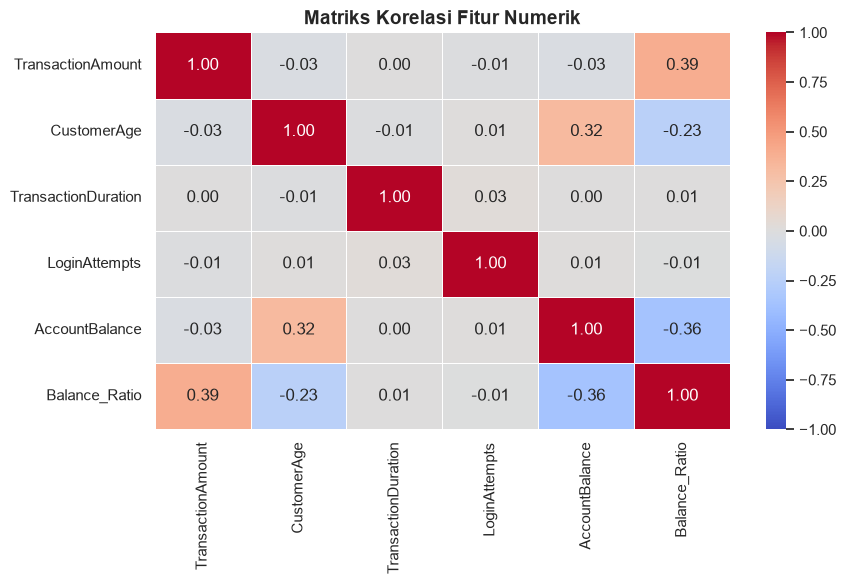

In [9]:
main_cat_cols = ['TransactionType', 'Channel', 'CustomerOccupation']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, main_cat_cols):
    order_vals = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order_vals, palette='viridis', ax=ax)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Jumlah Transaksi')

plt.suptitle('Distribusi Fitur Kategorikal Utama', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriks Korelasi Fitur Numerik', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---

# 4. Seleksi Fitur & Standarisasi (Preprocessing)
Tiga aturan preprocessing sebelum masuk ke **K-Means**:
1. **Pertahankan *outlier* alami**: `LoginAttempts > 1`, nominal besar, dan `Balance_Ratio` tinggi adalah sinyal anomali yang ingin dideteksi.
2. **Pakai 6 fitur numerik saja**: K-Means memakai jarak Euclidean, sehingga fitur teks (`Location`, `Channel`, dll.) tidak di-encode agar tidak memunculkan jarak urutan palsu. Fitur teks tetap disimpan untuk analisis profil dan filter dashboard.
3. **Standarisasi (`StandardScaler`)**: samakan skala ke `mean = 0` dan `std = 1` supaya `AccountBalance` (ribuan USD) tidak mendominasi `LoginAttempts` (satuan).

In [10]:
clustering_features = [
    'TransactionAmount', 'CustomerAge', 'TransactionDuration',
    'LoginAttempts', 'AccountBalance', 'Balance_Ratio'
]

scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df[clustering_features]),
    columns=clustering_features
)

print(f"Ukuran df_scaled: {df_scaled.shape[0]} baris, {df_scaled.shape[1]} fitur")
df_scaled.head()

Ukuran df_scaled: 2516 baris, 6 fitur


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance,Balance_Ratio
0,-0.97,1.43,-0.55,-0.20,-0.00,-0.38
1,0.27,1.32,0.31,-0.20,2.23,-0.33
2,-0.59,-1.44,-0.91,-0.20,-1.03,-0.17
3,-0.39,-1.05,-1.36,-0.20,0.89,-0.35
4,-0.97,0.02,1.13,-0.20,0.60,-0.38


## 4.1 Cek Kesetaraan Varians
Pastikan semua fitur di `df_scaled` punya `mean = 0.00`, `std = 1.00`, dan `variance = 1.00`.

In [11]:
scaled_summary = df_scaled.describe().T
scaled_summary['variance'] = df_scaled.var()

print("=== Statistik & Varians Setelah StandardScaler ===")
display(scaled_summary[['count', 'mean', 'std', 'variance', 'min', '50%', 'max']])

=== Statistik & Varians Setelah StandardScaler ===


,count,mean,std,variance,min,50%,max
TransactionAmount,2516.00,-0.00,1.00,1.00,-1.02,-0.29,5.57
CustomerAge,2516.00,0.00,1.00,1.00,-1.50,0.02,1.99
TransactionDuration,2516.00,0.00,1.00,1.00,-1.57,-0.10,2.59
LoginAttempts,2516.00,-0.00,1.00,1.00,-0.20,-0.20,6.53
AccountBalance,2516.00,0.00,1.00,1.00,-1.29,-0.10,2.55
Balance_Ratio,2516.00,0.00,1.00,1.00,-0.39,-0.29,15.11


---

# 5. Penentuan Jumlah Cluster & Pemodelan K-Means
Uji `k = 2` sampai `k = 8` memakai dua metrik:
- **Elbow Method (*Inertia* / WCSS)**: cari titik siku di mana penurunan jarak dalam cluster mulai melandai.
- **Silhouette Score**: cari nilai tertinggi (rentang `-1` sampai `1`) sebagai tanda pemisahan antar cluster paling jelas.

=== Evaluasi k = 2 s/d 8 ===


,k,Inertia,Silhouette Score
0,2,12329.12,0.2445
1,3,10169.29,0.2657
2,4,8589.45,0.2352
3,5,7503.40,0.2346
4,6,6536.45,0.2394
5,7,5778.12,0.2521
6,8,5276.25,0.2553



k optimal: 3 (Silhouette Score = 0.2657)


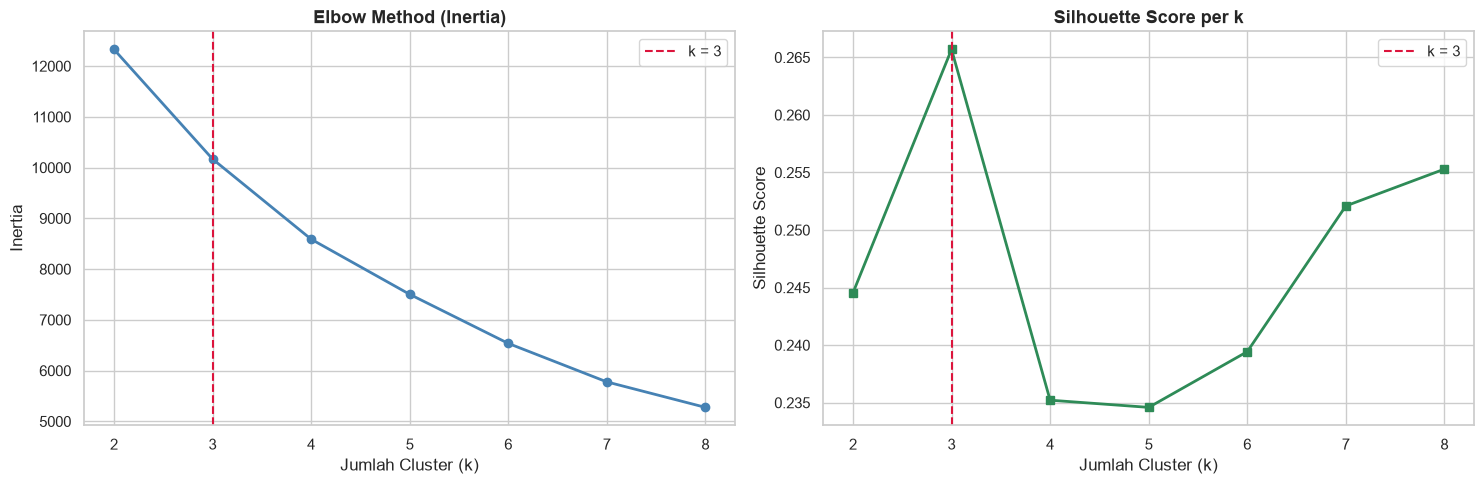

In [12]:
k_range = range(2, 9)
inertia_values = []
silhouette_values = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(df_scaled)
    inertia_values.append(km.inertia_)
    silhouette_values.append(silhouette_score(df_scaled, labels))

eval_df = pd.DataFrame({
    'k': list(k_range),
    'Inertia': inertia_values,
    'Silhouette Score': silhouette_values
})
print("=== Evaluasi k = 2 s/d 8 ===")
display(eval_df.assign(**{'Silhouette Score': eval_df['Silhouette Score'].map('{:.4f}'.format)}))

best_k = eval_df.loc[eval_df['Silhouette Score'].idxmax(), 'k']
best_sil = eval_df['Silhouette Score'].max()
print(f"\nk optimal: {best_k} (Silhouette Score = {best_sil:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
metrics = [
    (inertia_values, 'o', 'steelblue', 'Elbow Method (Inertia)', 'Inertia'),
    (silhouette_values, 's', 'seagreen', 'Silhouette Score per k', 'Silhouette Score')
]
for ax, (vals, marker, color, title, ylabel) in zip(axes, metrics):
    ax.plot(k_range, vals, marker=marker, linewidth=2, color=color)
    ax.axvline(x=best_k, color='crimson', linestyle='--', label=f'k = {best_k}')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Jumlah Cluster (k)')
    ax.set_ylabel(ylabel)
    ax.legend()

plt.tight_layout()
plt.show()

## 5.1 Model Final (`k = 3`) & Visualisasi PCA 2D
`k = 3` memberi **Silhouette Score tertinggi** (`0.2657`). Pakai **PCA** untuk mereduksi 6 fitur menjadi 2 komponen (`PC1`, `PC2`) agar sebaran cluster dan *centroid* bisa digambar di grafik 2D.

=== Distribusi Anggota per Cluster ===


,Jumlah Transaksi,Persentase (%)
Cluster,,
0,1596,63.43
1,827,32.87
2,93,3.70


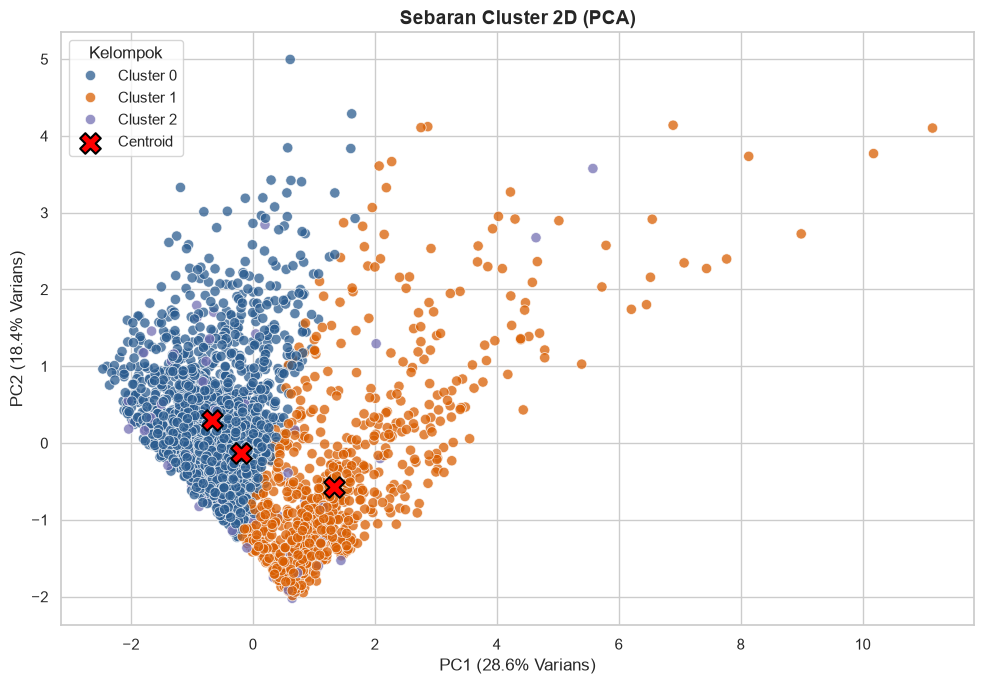

In [13]:
optimal_k = 3
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(df_scaled)

cluster_dist = pd.DataFrame({
    'Jumlah Transaksi': pd.Series(cluster_labels).value_counts().sort_index(),
    'Persentase (%)': pd.Series(cluster_labels).value_counts(normalize=True).sort_index() * 100
})
cluster_dist.index.name = 'Cluster'
print("=== Distribusi Anggota per Cluster ===")
display(cluster_dist)

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(df_scaled)
centers_df = pd.DataFrame(kmeans_model.cluster_centers_, columns=clustering_features)
centroids_pca = pca.transform(centers_df)

df_pca = pd.DataFrame(pca_coords, columns=['PC1', 'PC2'])
df_pca['Cluster'] = [f'Cluster {c}' for c in cluster_labels]

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_pca, x='PC1', y='PC2', hue='Cluster',
    palette=['#2b5c8f', '#d95f02', '#7570b3'],
    hue_order=['Cluster 0', 'Cluster 1', 'Cluster 2'],
    alpha=0.75, s=55
)
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c='red', s=220, marker='X', edgecolors='black', linewidths=1.5, label='Centroid'
)

var_pc1, var_pc2 = pca.explained_variance_ratio_ * 100
plt.title('Sebaran Cluster 2D (PCA)', fontsize=14, fontweight='bold')
plt.xlabel(f'PC1 ({var_pc1:.1f}% Varians)')
plt.ylabel(f'PC2 ({var_pc2:.1f}% Varians)')
plt.legend(title='Kelompok')
plt.tight_layout()
plt.show()

---

# 6. Profiling Cluster, Interpretasi, & Ekspor Data
Kembalikan label `Cluster` ke data skala asli (`df`) agar profil tiap segmen mudah dibaca dalam satuan USD, tahun, dan detik.

In [14]:
df['Cluster'] = cluster_labels

print("=== Rata-Rata (Mean) per Cluster ===")
display(df.groupby('Cluster')[clustering_features].mean())

print("\n=== Nilai Tengah (Median) per Cluster ===")
display(df.groupby('Cluster')[clustering_features].median())

print("\n=== Kategori Dominan (Modus) per Cluster ===")
display(df.groupby('Cluster')[categorical_cols].agg(lambda x: x.mode()[0]))

=== Rata-Rata (Mean) per Cluster ===


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance,Balance_Ratio
Cluster,,,,,,
0,272.13,53.67,117.63,1.01,6933.26,0.05
1,347.13,27.25,121.76,1.01,1578.34,0.48
2,274.00,44.57,130.77,4.00,5318.53,0.17



=== Nilai Tengah (Median) per Cluster ===


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance,Balance_Ratio
Cluster,,,,,,
0,199.94,55.00,112.00,1.00,6724.34,0.03
1,242.39,25.00,113.00,1.00,1145.23,0.20
2,192.23,47.00,127.00,4.00,4815.11,0.05



=== Kategori Dominan (Modus) per Cluster ===


,TransactionType,Location,Channel,CustomerOccupation
Cluster,,,,
0,Debit,Fort Worth,Branch,Retired
1,Debit,Los Angeles,Branch,Student
2,Debit,Fort Worth,Online,Doctor


## 6.1 Perbandingan Fitur Utama Antar Cluster
Bandingkan 4 fitur pembeda (`CustomerAge`, `AccountBalance`, `Balance_Ratio`, `LoginAttempts`) lewat boxplot.

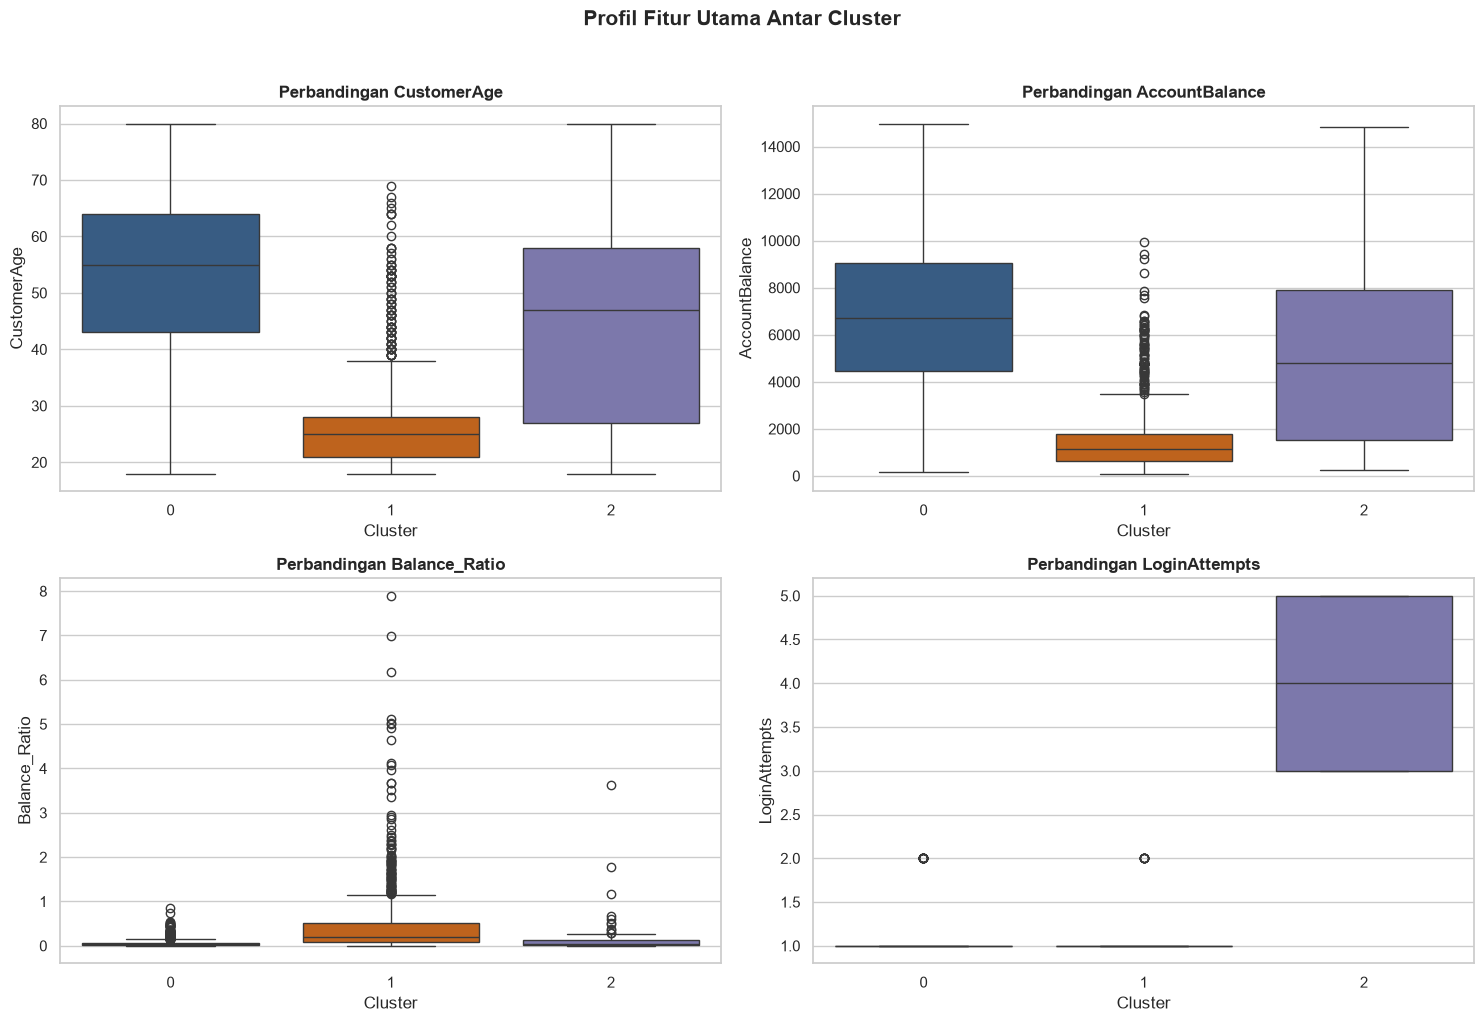

In [15]:
key_features = ['CustomerAge', 'AccountBalance', 'Balance_Ratio', 'LoginAttempts']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, col in zip(axes.flatten(), key_features):
    sns.boxplot(
        data=df, x='Cluster', y=col,
        palette=['#2b5c8f', '#d95f02', '#7570b3'], ax=ax
    )
    ax.set_title(f'Perbandingan {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Cluster')
    ax.set_ylabel(col)

plt.suptitle('Profil Fitur Utama Antar Cluster', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 6.2 Interpretasi & Rekomendasi Bisnis

### Cluster 0 — Nasabah Mapan Konservatif (`1,596` transaksi / `63.43%`)
* **Profil**: Rata-rata usia `53.67` tahun (dominan `Retired`, kanal `Branch`), saldo tertinggi (`6,933.26` USD), transaksi `272.13` USD, **`Balance_Ratio` hanya `0.05`**, dan `LoginAttempts` normal (`1.01`, rentang `1–2`).
* **Tindakan**: Nasabah inti dengan dana mengendap besar dan belanja aman. Tawarkan deposito berjangka, obligasi, atau reksa dana risiko rendah.

### Cluster 1 — Nasabah Muda Aktif (`827` transaksi / `32.87%`)
* **Profil**: Rata-rata usia `27.25` tahun (dominan `Student`, kanal `Branch`), saldo terendah (`1,578.34` USD), transaksi tertinggi (`347.13` USD), **`Balance_Ratio` mencapai `0.48`**, dan `LoginAttempts` normal (`1.01`, rentang `1–2`).
* **Tindakan**: Aktif belanja dengan porsi penarikan besar terhadap saldo. Tawarkan tabungan *auto-debit*, fitur batas pengeluaran (*budgeting alert*), atau promo *cashback*.

### Cluster 2 — Transaksi Berisiko / Anomali Login (`93` transaksi / `3.70%`)
* **Profil**: Mengisolasi seluruh transaksi dengan **`LoginAttempts` `3–5` kali** (rata-rata `4.00`), durasi paling lama (`130.77` detik), saldo rata-rata `5,318.53` USD, usia `44.57` tahun, dominan `Doctor` dan kanal **`Online`**.
* **Tindakan**: Indikasi kuat percobaan pembobolan atau anomali akses. Terapkan OTP/2FA wajib, notifikasi peringatan instan, dan verifikasi manual bila `LoginAttempts >= 3`.

## 6.3 Simpan Data & Model
Ekspor data berlabel (`data_clustering_clean.csv`) plus `StandardScaler` dan `KMeans` (`.joblib`) untuk Fase 2 (Klasifikasi) dan Fase 3 (Dashboard).

In [16]:
cluster_name_map = {
    0: '0 - Nasabah Mapan Konservatif',
    1: '1 - Nasabah Muda Aktif',
    2: '2 - Transaksi Berisiko (Anomali Login)'
}
df['Segment_Name'] = df['Cluster'].map(cluster_name_map)

df.to_csv('data_clustering_clean.csv', index=False)
joblib.dump(scaler, 'scaler_clustering.joblib')
joblib.dump(kmeans_model, 'kmeans_model.joblib')

print("File tersimpan:")
print(f"- data_clustering_clean.csv ({df.shape[0]} baris, {df.shape[1]} kolom)")
print("- scaler_clustering.joblib")
print("- kmeans_model.joblib\n")

df.head()

File tersimpan:
- data_clustering_clean.csv (2516 baris, 12 kolom)
- scaler_clustering.joblib
- kmeans_model.joblib



,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Balance_Ratio,Cluster,Segment_Name
0,14.09,Debit,San Diego,ATM,70.00,Doctor,81.00,1.00,5112.21,0.00,0,0 - Nasabah Mapan Konservatif
1,376.24,Debit,Houston,ATM,68.00,Doctor,141.00,1.00,13758.91,0.03,0,0 - Nasabah Mapan Konservatif
2,126.29,Debit,Mesa,Online,19.00,Student,56.00,1.00,1122.35,0.11,1,1 - Nasabah Muda Aktif
3,184.50,Debit,Raleigh,Online,26.00,Student,25.00,1.00,8569.06,0.02,0,0 - Nasabah Mapan Konservatif
4,13.45,Credit,Atlanta,Online,45.00,Student,198.00,1.00,7429.40,0.00,0,0 - Nasabah Mapan Konservatif
